In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y número de operarios necesarios por actividad se adjunta. La empresa sólo dispone de 6 operarios durante las 3 primeras semanas y de 8 a partir de entonces.

In [4]:
pregunta_1 = "1. Dibuje el diagrama de cargas con las actividades en su inicio más temprano y compruebe si se respeta el límite de operarios.  "
pregunta_2 = "2. Reprograme el proyecto con el algoritmo de asignación de Wiest-Levy para respetar el límite. ¿Qué actividades se desplazan y cuánto se alarga el proyecto?  "
pregunta_3 = "3. ¿Y si se dispusiera de 6 operarios durante todo el proyecto? Compare las dos duraciones.  "
pregunta_4 = "4. Explique por qué la asignación puede alargar el proyecto y la nivelación nunca.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el diagrama de cargas con las actividades en su inicio más temprano y compruebe si se respeta el límite de operarios.  

2. Reprograme el proyecto con el algoritmo de asignación de Wiest-Levy para respetar el límite. ¿Qué actividades se desplazan y cuánto se alarga el proyecto?  

3. ¿Y si se dispusiera de 6 operarios durante todo el proyecto? Compare las dos duraciones.  

4. Explique por qué la asignación puede alargar el proyecto y la nivelación nunca.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 2       , 4        ),
    ('B'     , '---'      , 3       , 4        ),
    ('C'     , '---'      , 2       , 2        ),
    ('D'     , 'A,C'      , 5       , 4        ),
    ('E'     , 'B'        , 6       , 3        ),
    ('F'     , 'B,D'      , 6       , 1        ),
    ('G'     , 'C'        , 3       , 4        ),
    ('H'     , 'D,E,G'    , 8       , 2        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,2,4
B,---,3,4
C,---,2,2
D,"A,C",5,4
E,B,6,3
F,"B,D",6,1
G,C,3,4
H,"D,E,G",8,2


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el diagrama de cargas con las actividades en su inicio más temprano y compruebe si se respeta el límite de operarios.  

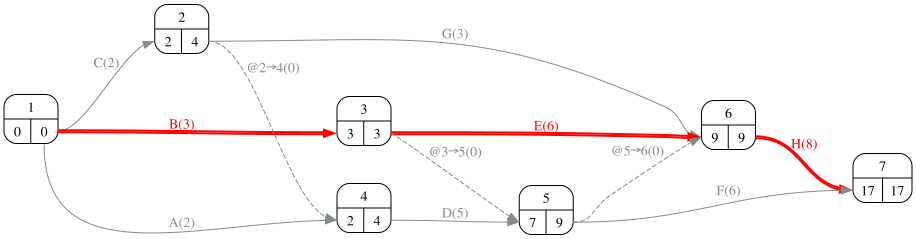

In [8]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

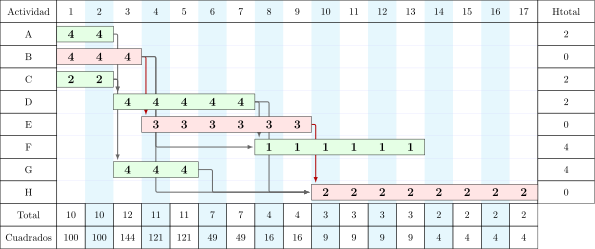

In [9]:
#| fig-cap: "Diagrama de Gantt con las cargas de operarios (inicios más tempranos)"
#| label: fig-ganttInicial
proyecto_inicial = proyecto.copy()
gantt_inicial, dibujo = proyecto_inicial.gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

In [10]:
limite_maximo_recursos = [6] * 3 + [8]

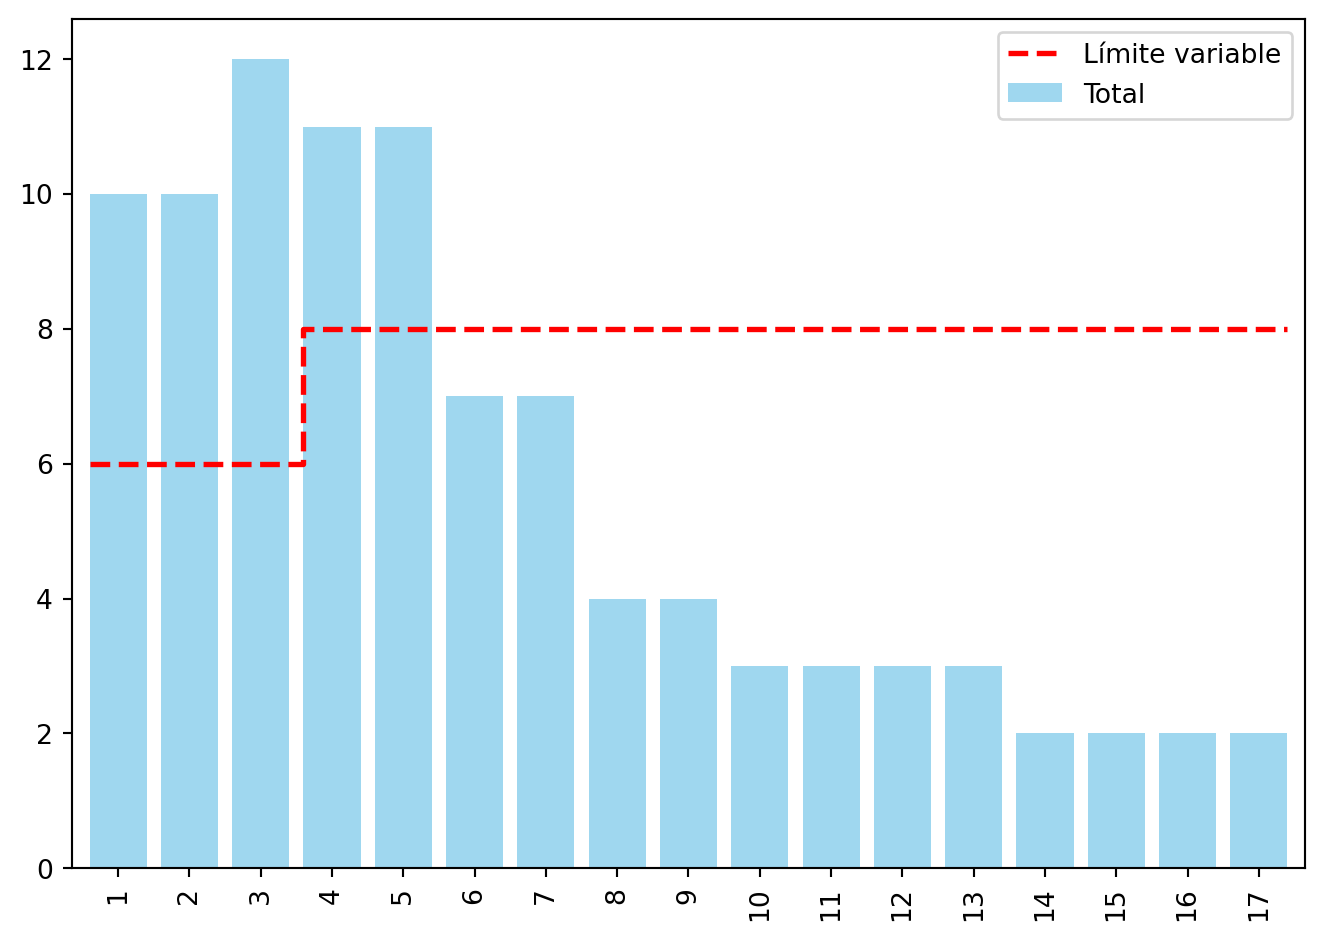

In [11]:
#| fig-cap: "Diagrama de cargas con el límite de operarios"
#| label: fig-cargasInicial
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=limite_maximo_recursos)

In [12]:
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
limite = pd.Series([limite_maximo_recursos[min(t - 1, len(limite_maximo_recursos) - 1)] for t in range(1, len(cargas) + 1)], index=cargas.index)
exceso = cargas[cargas > limite]
Markdown(f'El límite se supera en las semanas {", ".join(str(t) for t in exceso.index)}: hacen falta hasta {int(cargas.max())} operarios.')

El límite se supera en las semanas 1, 2, 3, 4, 5: hacen falta hasta 12 operarios.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. Reprograme el proyecto con el algoritmo de asignación de Wiest-Levy para respetar el límite. ¿Qué actividades se desplazan y cuánto se alarga el proyecto?  

El algoritmo de Wiest-Levy recorre el calendario periodo a periodo: cuando la demanda supera el límite, aplaza las actividades con más holgura (y, si no basta, también críticas, lo que alarga el proyecto). Las filas 💤 marcan las esperas introducidas.

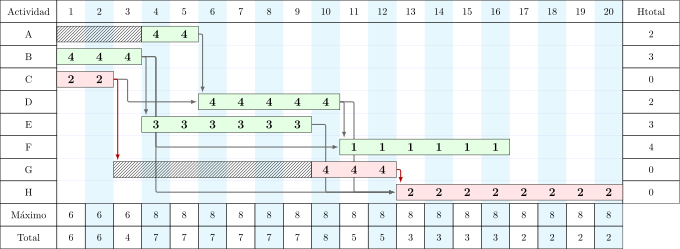

In [14]:
#| fig-cap: "Diagrama de Gantt tras la asignación"
#| label: fig-ganttAsignado
proyecto_asignado = proyecto.copy()
datos_asignados, gantt_asignado, dibujo = proyecto_asignado.asignar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources',
    maximo=limite_maximo_recursos, report=False, params=dict(period_width=1, **GANTT_PARAMS))
pinta_tikz(dibujo)

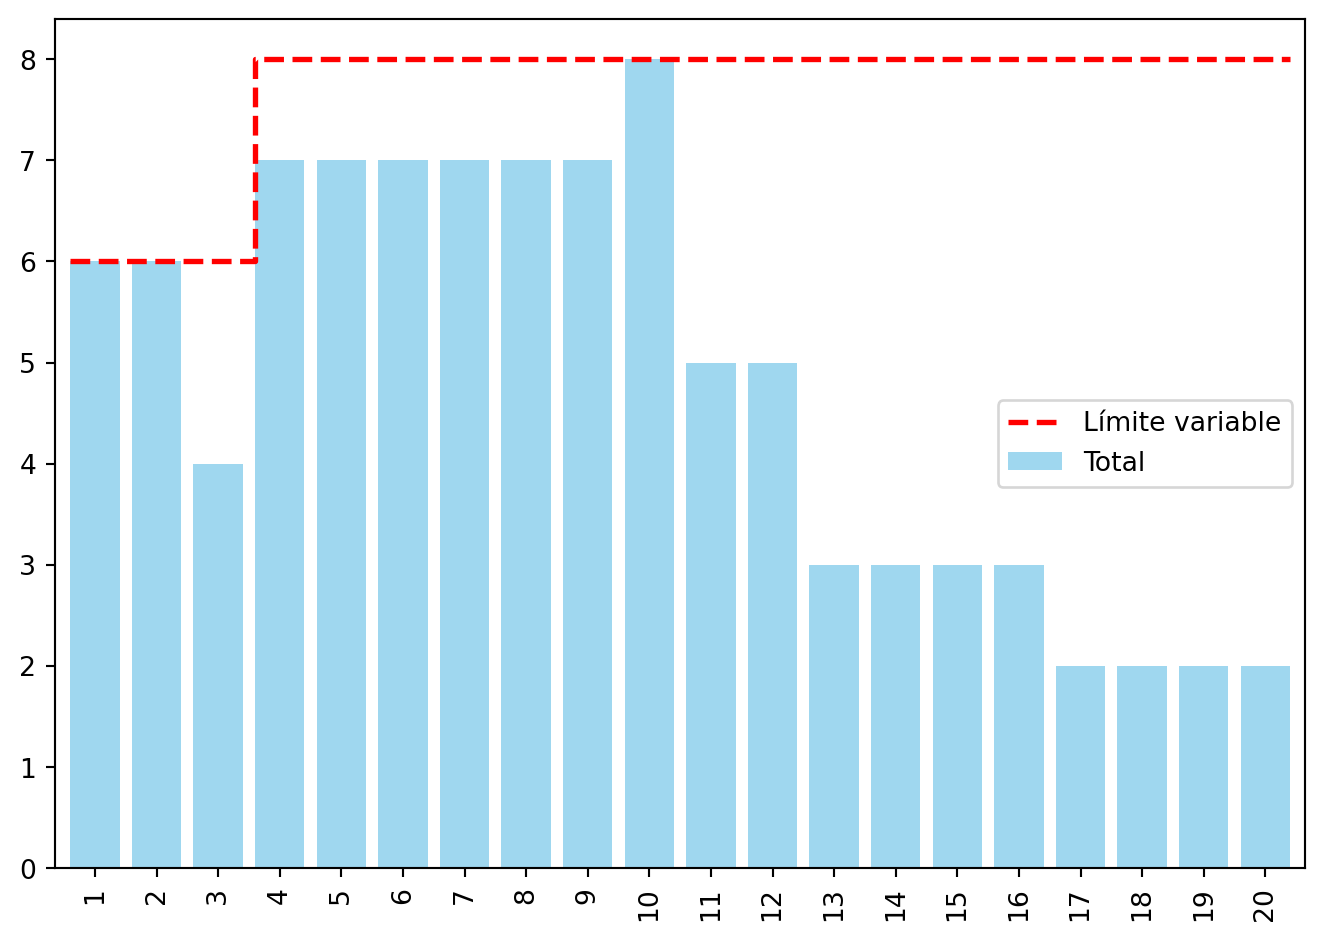

In [15]:
#| fig-cap: "Diagrama de cargas tras la asignación"
#| label: fig-cargasAsignado
plot_cargas(gantt_df=gantt_asignado, limite_maximo_recursos=limite_maximo_recursos)

In [16]:
duracion_inicial = proyecto.duration(datos_proyecto['duration'])
duracion_asignada = len(gantt_asignado.data.columns.drop('H_total'))
esperas = datos_asignados[datos_asignados.index.str.startswith('💤')]
Markdown(f'El proyecto pasa de {duracion_inicial} a {duracion_asignada} semanas. Esperas introducidas: '
         f'{", ".join(f"{i[1:]} ({int(fila.duration)} sem.)" for i, fila in esperas.iterrows()) or "ninguna"}.')

El proyecto pasa de 17 a 20 semanas. Esperas introducidas: A (3 sem.), G (7 sem.).

## Apartado 3

In [17]:
display(Markdown(pregunta_3))

3. ¿Y si se dispusiera de 6 operarios durante todo el proyecto? Compare las dos duraciones.  

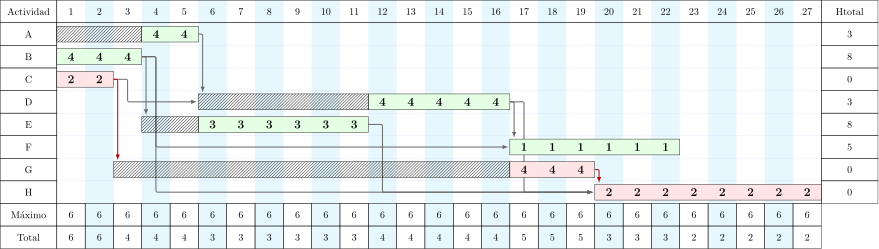

In [18]:
#| fig-cap: "Diagrama de Gantt con el límite constante"
#| label: fig-ganttLimiteFijo
limite_fijo = [6]
proyecto_fijo = proyecto.copy()
datos_fijo, gantt_fijo, dibujo = proyecto_fijo.asignar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources',
    maximo=limite_fijo, report=False, params=dict(period_width=1, **GANTT_PARAMS))
pinta_tikz(dibujo)

In [19]:
duracion_fija = len(gantt_fijo.data.columns.drop('H_total'))
Markdown(f'Con 6 operarios durante todo el proyecto la duración sería de {duracion_fija} semanas, frente a {duracion_asignada} con el refuerzo a partir de la semana 3.')

Con 6 operarios durante todo el proyecto la duración sería de 27 semanas, frente a 20 con el refuerzo a partir de la semana 3.

## Apartado 4

In [20]:
display(Markdown(pregunta_4))

4. Explique por qué la asignación puede alargar el proyecto y la nivelación nunca.  

La nivelación sólo usa las holguras: desplaza actividades no críticas sin tocar el plazo. La asignación impone una restricción dura; si en algún periodo ni siquiera aplazando todas las actividades con holgura cabe la demanda, tiene que aplazar actividades críticas y el proyecto se alarga.